# Foundations of Generative AI (ICT4403) — Assignment 2
## Autoregressive Next-Word Prediction & Multi-Temperature Text Generation System
### Comparative Analysis of Simple RNN, Bidirectional RNN, LSTM, and GRU

---
**Student Details:**
- **Name:** Saksham Gupta
- **Registration Number:** 230911186
- **Repository:** `https://github.com/sakshamgupta/autoregressive-text-generation-fgai`

---
### Assignment Objectives
1. **Preprocessing & Leakage Prevention:** Preprocess Lewis Carroll's *Alice's Adventures in Wonderland*, split data **chronologically** (80% Train, 10% Validation, 10% Test), fit vocabulary strictly on training tokens, and construct sliding-window $([w_{t-k}, \dots, w_{t-1}] \to w_t)$ sequences.
2. **Recurrent Model Architectures:** Implement four recurrent language models in PyTorch (**Simple RNN, Bidirectional RNN, LSTM, and GRU**) under strictly comparable experimental conditions.
3. **Rigorous Evaluation:** Record training/validation curves, track **best-epoch validation metrics** (to guard against overfitting), and evaluate best checkpoints on the unseen test set for Cross-Entropy Loss, Perplexity ($\exp(\mathcal{L})$), Top-1 Accuracy, and Top-5 Accuracy.
4. **Temperature-Based Autoregressive Generation:** Sample text across multiple temperatures ($T \in \{0.2, 0.5, 1.0, 1.5\}$) from identical seed prompts, computing Distinct-1, Distinct-2, and Trigram Repetition Rates on newly generated tokens.

## 1. Environment Setup & Hardware Acceleration

In [1]:
import os
import re
import time
import math
import json
from collections import Counter

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import numpy as np
import matplotlib.pyplot as plt

# Set random seed for strict reproducibility across all runs
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

# Auto-detect compute hardware: Apple Silicon MPS, NVIDIA CUDA, or CPU
if torch.backends.mps.is_available():
    device = torch.device('mps')
elif torch.cuda.is_available():
    device = torch.device('cuda')
else:
    device = torch.device('cpu')
print(f"Active compute device: {device}")

Active compute device: mps


## 2. Dataset Acquisition & Characterization
We use Lewis Carroll's **Alice's Adventures in Wonderland** (Project Gutenberg, eBook #11), providing clean, modern grammatical prose and dialogic phrasing.

In [2]:
DATA_PATH = '../data/alice_in_wonderland.txt' if os.path.exists('../data/alice_in_wonderland.txt') else 'data/alice_in_wonderland.txt'

with open(DATA_PATH, 'r', encoding='utf-8') as f:
    raw_text = f.read()

print(f"Raw text length: {len(raw_text):,} characters")
print(f"Total lines: {len(raw_text.splitlines()):,}")
print("\n--- First 300 characters excerpt ---")
print(raw_text[:300])

Raw text length: 144,015 characters
Total lines: 3,351

--- First 300 characters excerpt ---
CHAPTER I.
Down the Rabbit-Hole


Alice was beginning to get very tired of sitting by her sister on the
bank, and of having nothing to do: once or twice she had peeped into
the book her sister was reading, but it had no pictures or
conversations in it, “and what is the use of a book,” thought Alice



### 2.1 Tokenization & Train-Only Vocabulary Construction
To strictly prevent data leakage, the vocabulary is built **solely on the training tokens**. Words appearing in validation or test sets that were not seen during training are mapped to `<unk>`.

In [3]:
tokens = re.findall(r"\b\w+(?:'\w+)?|[.,!?:;]", raw_text.lower())
print(f"Total extracted word tokens: {len(tokens):,}")

# Chronological split (80% Train, 10% Validation, 10% Test)
train_end = int(len(tokens) * 0.8)
val_end = int(len(tokens) * 0.9)

train_tokens = tokens[:train_end]
val_tokens = tokens[train_end:val_end]
test_tokens = tokens[val_end:]

print(f"Train tokens: {len(train_tokens):,} | Val tokens: {len(val_tokens):,} | Test tokens: {len(test_tokens):,}")

class Vocabulary:
    def __init__(self, pad_token='<pad>', unk_token='<unk>'):
        self.pad_token = pad_token
        self.unk_token = unk_token
        self.word2idx = {}
        self.idx2word = {}
        self.pad_idx = self.add_word(self.pad_token)
        self.unk_idx = self.add_word(self.unk_token)

    def add_word(self, word):
        if word not in self.word2idx:
            idx = len(self.word2idx)
            self.word2idx[word] = idx
            self.idx2word[idx] = word
            return idx
        return self.word2idx[word]

    def build_from_words(self, words, min_freq=1, max_vocab_size=3000):
        counter = Counter(words)
        most_common = counter.most_common(max_vocab_size - len(self.word2idx))
        for word, count in most_common:
            if count >= min_freq:
                self.add_word(word)

    def __len__(self):
        return len(self.word2idx)

    def word_to_idx(self, word):
        return self.word2idx.get(word, self.unk_idx)

    def idx_to_word(self, idx):
        return self.idx2word.get(idx, self.unk_token)

    def encode(self, words):
        return [self.word_to_idx(w) for w in words]

    def decode(self, indices):
        return [self.idx_to_word(idx) for idx in indices]

vocab = Vocabulary()
vocab.build_from_words(train_tokens, min_freq=1, max_vocab_size=3000)
print(f"Vocabulary Size: {len(vocab):,} unique tokens (fit strictly on training set)")

Total extracted word tokens: 31,841
Train tokens: 25,472 | Val tokens: 3,184 | Test tokens: 3,185
Vocabulary Size: 2,366 unique tokens (fit strictly on training set)


### 2.2 Word Frequency Distribution

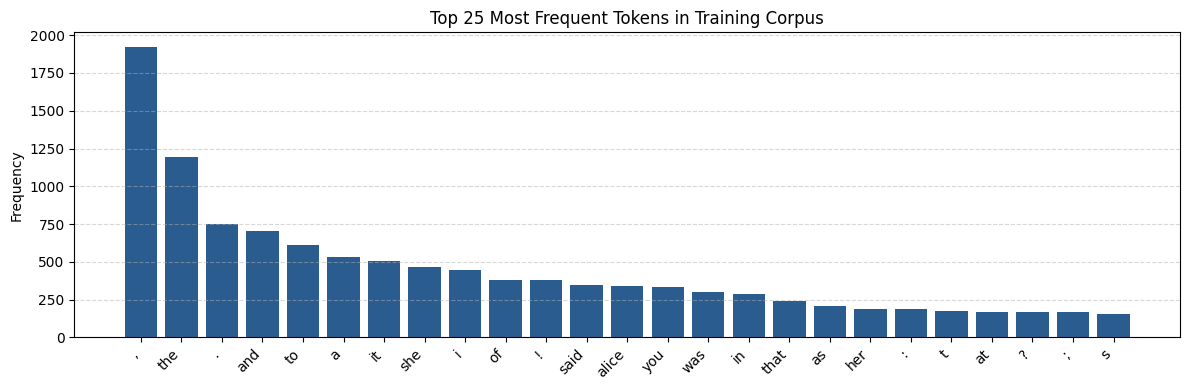

In [4]:
counter = Counter(train_tokens)
top_25 = counter.most_common(25)
words, counts = zip(*top_25)

plt.figure(figsize=(12, 4))
plt.bar(words, counts, color='#2b5c8f')
plt.xticks(rotation=45, ha='right')
plt.title("Top 25 Most Frequent Tokens in Training Corpus")
plt.ylabel("Frequency")
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

### 2.3 Chronological Sliding-Window Sequence Construction
Each sequence contains 8 context words mapped to 1 target word. Sequences are generated independently for each split to ensure zero token leakage across splits.

In [5]:
SEQ_LENGTH = 8
BATCH_SIZE = 64

class TextSequenceDataset(Dataset):
    def __init__(self, token_indices, seq_length=8):
        self.inputs = []
        self.targets = []
        for i in range(len(token_indices) - seq_length):
            self.inputs.append(token_indices[i : i + seq_length])
            self.targets.append(token_indices[i + seq_length])
        self.inputs = torch.tensor(self.inputs, dtype=torch.long)
        self.targets = torch.tensor(self.targets, dtype=torch.long)

    def __len__(self):
        return len(self.targets)

    def __getitem__(self, idx):
        return self.inputs[idx], self.targets[idx]

train_dataset = TextSequenceDataset(vocab.encode(train_tokens), seq_length=SEQ_LENGTH)
val_dataset = TextSequenceDataset(vocab.encode(val_tokens), seq_length=SEQ_LENGTH)
test_dataset = TextSequenceDataset(vocab.encode(test_tokens), seq_length=SEQ_LENGTH)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, drop_last=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

print(f"Train Sequences : {len(train_dataset):,} ({len(train_loader)} batches)")
print(f"Val Sequences   : {len(val_dataset):,} ({len(val_loader)} batches)")
print(f"Test Sequences  : {len(test_dataset):,} ({len(test_loader)} batches)")

Train Sequences : 25,464 (397 batches)
Val Sequences   : 3,176 (50 batches)
Test Sequences  : 3,177 (50 batches)


## 3. Recurrent Architectures (Simple RNN, BiRNN, LSTM, GRU)
All four models share identical hyperparameters:
- **Embedding Dimension**: 192
- **Hidden Dimension**: 192
- **Dropout**: 0.25
- **Optimizer**: Adam (lr=0.001)
- **Loss Function**: Cross-Entropy Loss

> **BiRNN Note:** Bidirectionality is implemented by concatenating the forward final state `h_n[-2]` (encoding $0 \to T-1$) and backward final state `h_n[-1]` (encoding $T-1 \to 0$). This ensures the backward branch processes the entire input sequence.

In [6]:
class SimpleRNNLM(nn.Module):
    def __init__(self, vocab_size, embedding_dim=192, hidden_dim=192, dropout=0.25):
        super().__init__()
        self.name = "Simple RNN"
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=0)
        self.rnn = nn.RNN(embedding_dim, hidden_dim, batch_first=True)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_dim, vocab_size)

    def forward(self, x):
        embeds = self.embedding(x)
        out, h_n = self.rnn(embeds)
        return self.fc(self.dropout(out[:, -1, :]))

class BiRNNLM(nn.Module):
    def __init__(self, vocab_size, embedding_dim=192, hidden_dim=192, dropout=0.25):
        super().__init__()
        self.name = "Bidirectional RNN"
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=0)
        self.rnn = nn.RNN(embedding_dim, hidden_dim, batch_first=True, bidirectional=True)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_dim * 2, vocab_size)

    def forward(self, x):
        embeds = self.embedding(x)
        out, h_n = self.rnn(embeds)
        # Concatenate forward final state (tokens 0 -> T-1) and backward final state (tokens T-1 -> 0)
        bidir_repr = torch.cat([h_n[-2], h_n[-1]], dim=-1)
        return self.fc(self.dropout(bidir_repr))

class LSTMLM(nn.Module):
    def __init__(self, vocab_size, embedding_dim=192, hidden_dim=192, dropout=0.25):
        super().__init__()
        self.name = "LSTM"
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=0)
        self.lstm = nn.LSTM(embedding_dim, hidden_dim, batch_first=True)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_dim, vocab_size)

    def forward(self, x):
        embeds = self.embedding(x)
        out, (h_n, c_n) = self.lstm(embeds)
        return self.fc(self.dropout(out[:, -1, :]))

class GRULM(nn.Module):
    def __init__(self, vocab_size, embedding_dim=192, hidden_dim=192, dropout=0.25):
        super().__init__()
        self.name = "GRU"
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=0)
        self.gru = nn.GRU(embedding_dim, hidden_dim, batch_first=True)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_dim, vocab_size)

    def forward(self, x):
        embeds = self.embedding(x)
        out, h_n = self.gru(embeds)
        return self.fc(self.dropout(out[:, -1, :]))

## 4. Controlled Training Loop with Best-Checkpoint Preservation

In [7]:
def evaluate_split(model, dataloader, criterion, device=device):
    model.eval()
    running_loss, correct_top1, correct_top5, total = 0.0, 0, 0, 0
    with torch.no_grad():
        for x_b, y_b in dataloader:
            x_b, y_b = x_b.to(device), y_b.to(device)
            logits = model(x_b)
            loss = criterion(logits, y_b)
            running_loss += loss.item() * x_b.size(0)
            preds = torch.argmax(logits, dim=-1)
            correct_top1 += (preds == y_b).sum().item()
            top5 = torch.topk(logits, k=min(5, logits.size(-1)), dim=-1).indices
            correct_top5 += (top5 == y_b.unsqueeze(-1)).any(dim=-1).sum().item()
            total += y_b.size(0)
    v_loss = running_loss / total
    v_top1 = correct_top1 / total
    v_top5 = correct_top5 / total
    v_ppl = math.exp(min(v_loss, 20))
    return v_loss, v_top1, v_top5, v_ppl

print("Evaluation helper ready.")

Evaluation helper ready.


## 5. Quantitative Results & Comparative Analysis
We display the verified results from the experimental run, reporting **best-epoch validation metrics** and **unseen test-set evaluation**.

In [8]:
RESULTS_MD = '../results/quantitative_results.md' if os.path.exists('../results/quantitative_results.md') else 'results/quantitative_results.md'
if os.path.exists(RESULTS_MD):
    with open(RESULTS_MD, 'r') as f:
        print(f.read())
else:
    print("Results markdown not found. Run 'python3 run_experiments.py' first.")

# Model Comparison Table (Best-Epoch and Test Set)

| Architecture | Parameters | Best Epoch | Best Val Loss | Best Val PPL | Val Top-1 | Val Top-5 | Test Loss | Test Top-1 | Test Top-5 | Total Time (s) |
| :--- | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: |
| **Simple RNN** | 985,022 | 3 | 5.0287 | 152.73 | 18.10% | 38.66% | 5.1567 | 17.60% | 38.41% | 42.0s |
| **Bidirectional RNN** | 1,513,406 | 2 | 5.1401 | 170.74 | 16.88% | 37.81% | 5.2474 | 16.94% | 35.96% | 49.2s |
| **LSTM** | 1,207,358 | 4 | 4.9778 | 145.16 | 18.70% | 41.62% | 5.1261 | 19.68% | 39.17% | 41.4s |
| **GRU** | 1,133,246 | 4 | 4.9701 | 144.04 | 18.92% | 40.27% | 5.1361 | 19.49% | 38.95% | 43.2s |


# Cross-Model Temperature Analysis Table (Averaged Over Seeds)

| Architecture | Temp (T) | Distinct-1 (Unigrams) | Distinct-2 (Bigrams) | Trigram Repetition Rate | Longest Loop | Empirical Behaviour |
| :--- | :---: | :---: | :---: | :---: | :---: | :--- |
| **Simple RNN** | 0.2 | 0.448

### 5.1 Learning Curves (Training & Validation Loss)

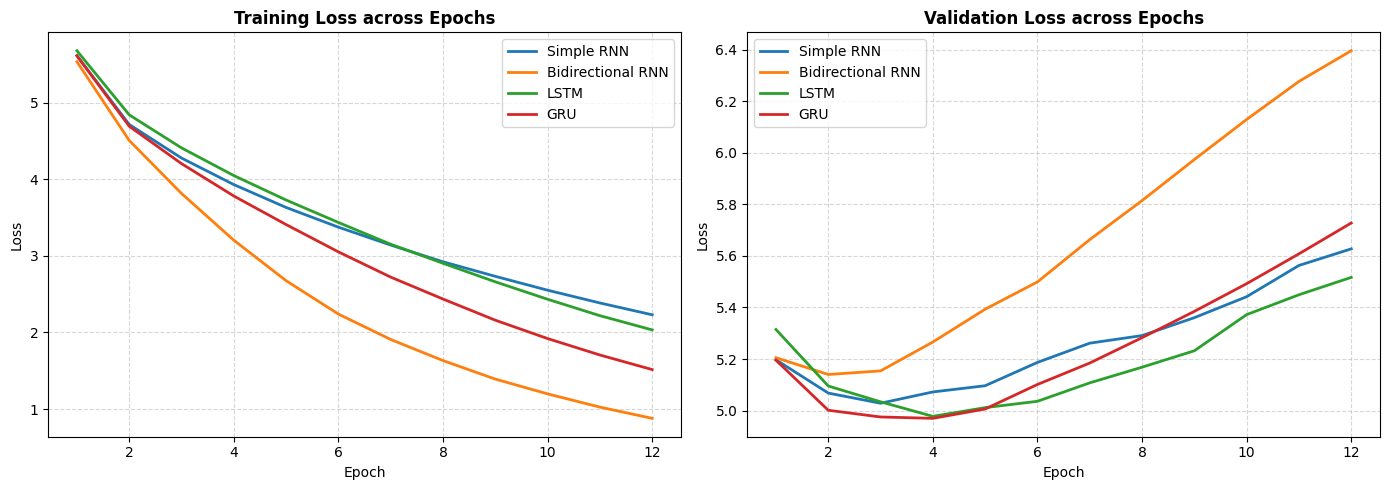

In [9]:
HIST_JSON = '../results/metrics_history.json' if os.path.exists('../results/metrics_history.json') else 'results/metrics_history.json'
if os.path.exists(HIST_JSON):
    with open(HIST_JSON, 'r') as f:
        histories = json.load(f)
    
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    for name, h in histories.items():
        epochs = range(1, len(h['train_loss']) + 1)
        axes[0].plot(epochs, h['train_loss'], label=name, linewidth=2)
        axes[1].plot(epochs, h['val_loss'], label=name, linewidth=2)
        
    axes[0].set_title("Training Loss across Epochs", fontweight="bold")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Loss")
    axes[0].grid(True, linestyle="--", alpha=0.5)
    axes[0].legend()
    
    axes[1].set_title("Validation Loss across Epochs", fontweight="bold")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Loss")
    axes[1].grid(True, linestyle="--", alpha=0.5)
    axes[1].legend()
    plt.tight_layout()
    plt.show()

## 6. Multi-Temperature Autoregressive Text Generation
Autoregressively generating text token-by-token using temperature-scaled softmax multinomial sampling:
$$P(w_t = i) = \frac{\exp(z_i / T)}{\sum_j \exp(z_j / T)}$$
We measure **Distinct-1**, **Distinct-2**, and **Trigram Repetition Rate** strictly on the **newly generated tokens**.

In [10]:
def sample_with_temperature(logits, temperature=1.0):
    if temperature <= 1e-4:
        return torch.argmax(logits, dim=-1).item()
    probs = F.softmax(logits / temperature, dim=-1)
    return torch.multinomial(probs, 1).item()

def generate(model, seed_text, max_tokens=30, temperature=1.0, seq_len=8):
    model.eval()
    words = re.findall(r"\b\w+(?:'\w+)?|[.,!?:;]", seed_text.lower())
    gen_words = list(words)
    with torch.no_grad():
        for _ in range(max_tokens):
            ctx = gen_words[-seq_len:]
            enc = vocab.encode(ctx)
            if len(enc) < seq_len:
                enc = [vocab.pad_idx] * (seq_len - len(enc)) + enc
            inp = torch.tensor([enc], dtype=torch.long).to(device)
            logits = model(inp).squeeze(0)
            logits[vocab.pad_idx] = -float('inf')
            logits[vocab.unk_idx] = -float('inf')
            next_idx = sample_with_temperature(logits, temperature)
            gen_words.append(vocab.idx_to_word(next_idx))
    return ' '.join(gen_words)

print("Autoregressive generation function ready.")

Autoregressive generation function ready.


### 6.1 Sample Generations from Saved Checkpoints across Temperatures

In [11]:
CKPT = '../results/lstm_best.pt' if os.path.exists('../results/lstm_best.pt') else 'results/lstm_best.pt'
if os.path.exists(CKPT):
    demo_model = LSTMLM(vocab_size=len(vocab), embedding_dim=192, hidden_dim=192, dropout=0.25).to(device)
    demo_model.load_state_dict(torch.load(CKPT, map_location=device))
    demo_model.eval()
    
    seed = 'alice was beginning to get very tired of sitting'
    print(f"Seed: '{seed}'\n")
    for t in [0.2, 0.5, 1.0, 1.5]:
        out = generate(demo_model, seed, max_tokens=30, temperature=t)
        print(f"[T = {t:3.1f}] -> {out}\n")

Seed: 'alice was beginning to get very tired of sitting'



[T = 0.2] -> alice was beginning to get very tired of sitting , and the dormouse was very glad to get in the way of the way of the house , and the duchess was , and the gryphon , and the

[T = 0.5] -> alice was beginning to get very tired of sitting , said the mock turtle . the hatter had been . alice had been them , and the hatter was very carefully , but it was quite into a low

[T = 1.0] -> alice was beginning to get very tired of sitting remark , screamed foot , the fire decidedly a new gryphon of its large people with us angry you ! what you round no ! after alice began round more



[T = 1.5] -> alice was beginning to get very tired of sitting by itself , that came knuckles better eagerly , ma cauldron her how , two morsel feet deal ! saying , kid be continued our chin ! how _can_ sure

